# 03 · Explaining the Model with SHAP

A good forecast is not enough for a trader: they need to know **why** the model expects a high or low price.

**SHAP** (SHapley Additive exPlanations) splits every prediction into one contribution per feature:

> prediction = average prediction + contribution₁ + contribution₂ + … + contributionₙ

- positive contribution → the feature pushed the price **up** for that hour
- negative contribution → it pushed the price **down**

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

from src.features.build import build_features
from src.models.explain import FEATURE_DESCRIPTIONS, explain_prediction, get_explainer
from src.models.train import TEST_START, load_model, time_split
from src.plot_style import PALETTE, TEXT_SECONDARY, apply_style

apply_style()
FIG_DIR = Path("../reports/figures")

df = pd.read_parquet("../data/processed/energy_weather.parquet")
X, y = build_features(df)
X_train, X_test, y_train, y_test = time_split(X, y, TEST_START)

model = load_model("lightgbm_price_24h")
explainer = get_explainer(model)
shap_values = explainer(X_test)   # one SHAP value per feature, for every hour of 2018
print(shap_values.values.shape)

(8760, 29)


**Sanity check:** for any hour, the base value plus all contributions must equal the model's prediction exactly.

In [2]:
i = 0
print(f"Base value + sum of contributions = {shap_values.base_values[i] + shap_values.values[i].sum():.4f}")
print(f"Model prediction                  = {model.predict(X_test.iloc[[i]])[0]:.4f}")

Base value + sum of contributions = 28.7033
Model prediction                  = 28.7033


## 1. Global view: which features matter most overall?

The average absolute SHAP value tells us how much, on average, each feature moves the forecast (in €/MWh).

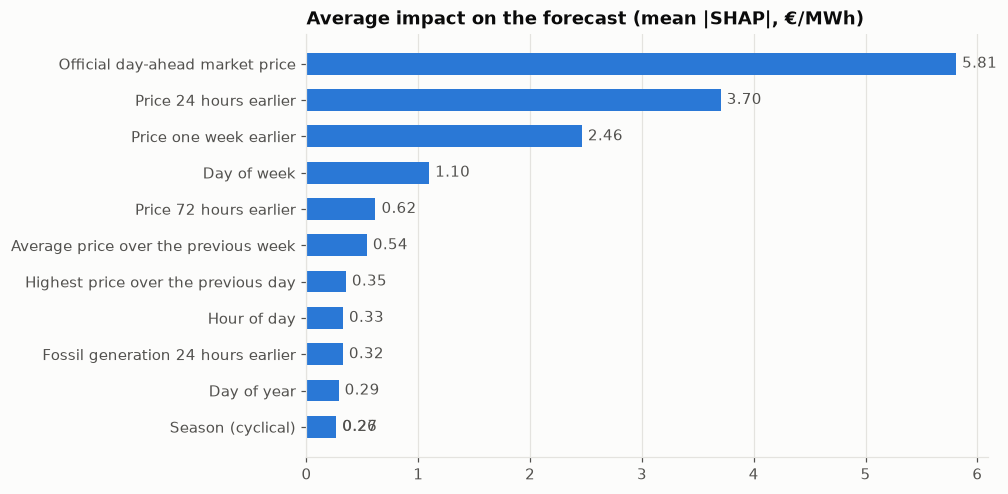

In [3]:
mean_abs = pd.Series(np.abs(shap_values.values).mean(axis=0), index=X_test.columns).sort_values().tail(12)
labels = [FEATURE_DESCRIPTIONS.get(c, c) for c in mean_abs.index]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(labels, mean_abs.values, color=PALETTE[0], height=0.6)
ax.bar_label(bars, fmt="%.2f", padding=4, color=TEXT_SECONDARY)
ax.set_title("Average impact on the forecast (mean |SHAP|, €/MWh)")
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "shap_importance.png")
plt.show()

The beeswarm plot adds **direction**: each dot is one hour of 2018, its colour is the feature value (red = high, blue = low),
and its position shows whether it pushed the price up (right) or down (left).

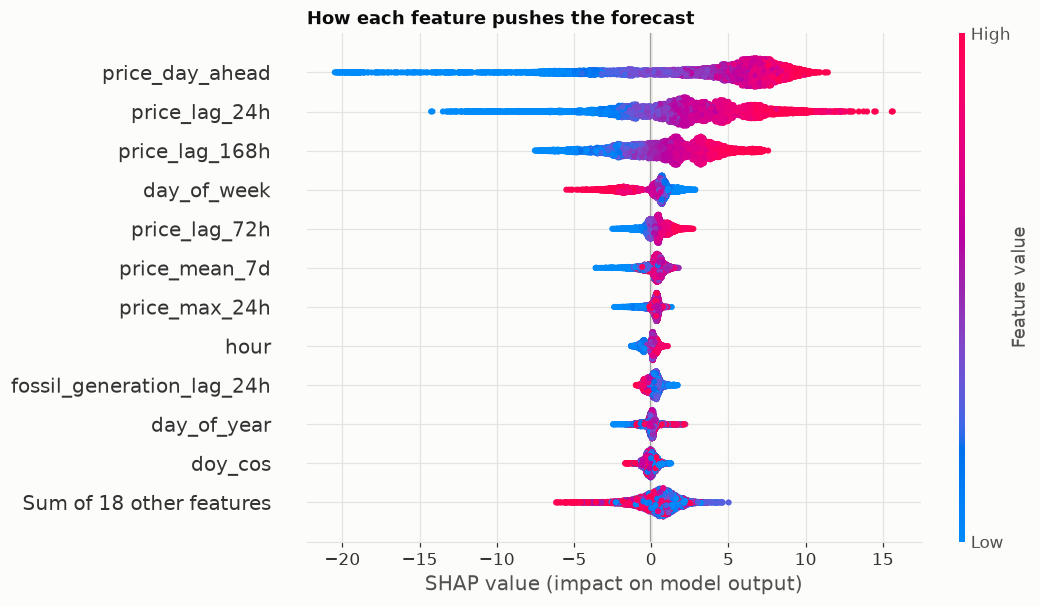

In [4]:
shap.plots.beeswarm(shap_values, max_display=12, show=False)
plt.gcf().set_size_inches(9, 6)
plt.title("How each feature pushes the forecast", loc="left", fontweight="bold")
plt.savefig(FIG_DIR / "shap_beeswarm.png")
plt.show()

## 2. How does wind affect the forecast?

A dependence plot shows a single feature's value (x-axis) against its SHAP contribution (y-axis).

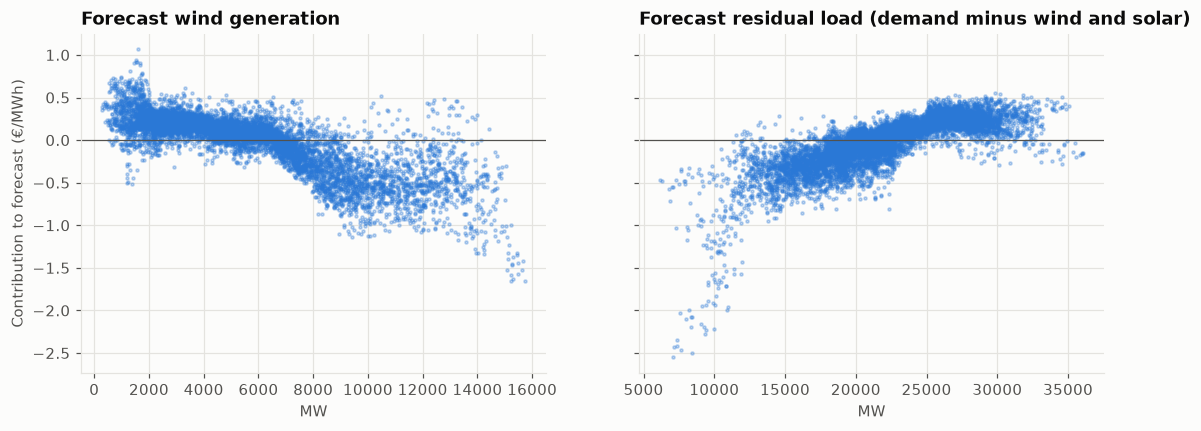

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, col in zip(axes, ["forecast_wind_onshore_day_ahead", "residual_load_forecast"]):
    j = X_test.columns.get_loc(col)
    ax.scatter(X_test[col], shap_values.values[:, j], s=4, alpha=0.3, color=PALETTE[0])
    ax.axhline(0, color=TEXT_SECONDARY, linewidth=0.8)
    ax.set_title(FEATURE_DESCRIPTIONS[col])
    ax.set_xlabel("MW")
axes[0].set_ylabel("Contribution to forecast (€/MWh)")
fig.savefig(FIG_DIR / "shap_wind_residual_load.png")
plt.show()

## 3. Explaining single forecasts

This is what the LLM agent will use: `explain_prediction()` returns the top drivers behind one specific forecast.
Let's look at the most expensive and the cheapest hour the model predicted in 2018.

In [6]:
predictions = pd.Series(model.predict(X_test), index=X_test.index)
expensive_hour = predictions.idxmax()
cheap_hour = predictions.idxmin()

explain_prediction(explainer, X_test, expensive_hour)

{'timestamp': '2018-09-18 20:00:00+02:00',
 'base_value': 55.97,
 'prediction': 88.57,
 'top_drivers': [{'feature': 'price_lag_24h',
   'description': 'Price 24 hours earlier',
   'value': 87.14,
   'contribution': 11.25},
  {'feature': 'price_day_ahead',
   'description': 'Official day-ahead market price',
   'value': 81.1,
   'contribution': 10.3},
  {'feature': 'price_lag_168h',
   'description': 'Price one week earlier',
   'value': 85.84,
   'contribution': 7.15},
  {'feature': 'price_lag_72h',
   'description': 'Price 72 hours earlier',
   'value': 82.76,
   'contribution': 1.48},
  {'feature': 'day_of_week',
   'description': 'Day of week',
   'value': 1.0,
   'contribution': 0.9}]}

In [7]:
explain_prediction(explainer, X_test, cheap_hour)

{'timestamp': '2018-04-01 04:00:00+02:00',
 'base_value': 55.97,
 'prediction': 13.9,
 'top_drivers': [{'feature': 'price_day_ahead',
   'description': 'Official day-ahead market price',
   'value': 4.99,
   'contribution': -17.08},
  {'feature': 'price_lag_24h',
   'description': 'Price 24 hours earlier',
   'value': 11.04,
   'contribution': -12.02},
  {'feature': 'price_lag_168h',
   'description': 'Price one week earlier',
   'value': 44.03,
   'contribution': -2.89},
  {'feature': 'doy_sin',
   'description': 'Season (cyclical)',
   'value': 1.0,
   'contribution': -2.54},
  {'feature': 'day_of_week',
   'description': 'Day of week',
   'value': 6.0,
   'contribution': -2.19}]}

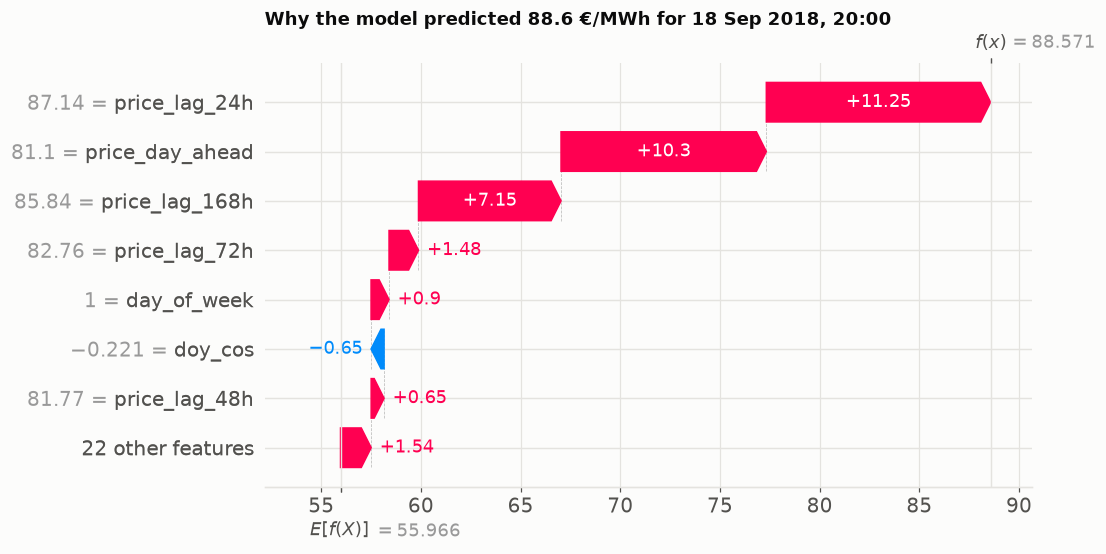

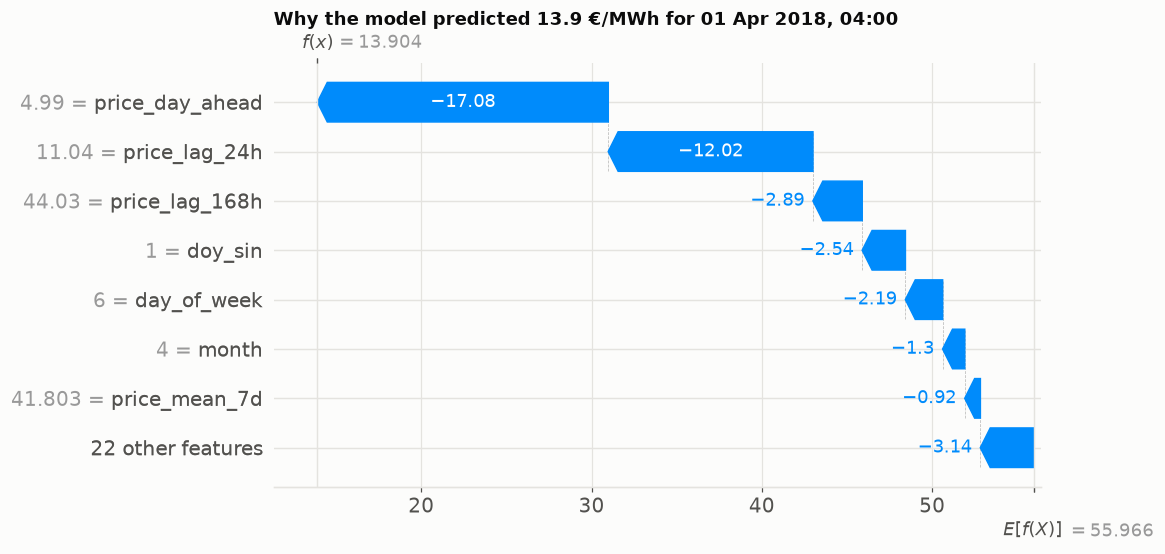

In [8]:
for hour, name in [(expensive_hour, "shap_waterfall_expensive.png"), (cheap_hour, "shap_waterfall_cheap.png")]:
    idx = X_test.index.get_loc(hour)
    shap.plots.waterfall(shap_values[idx], max_display=8, show=False)
    plt.title(f"Why the model predicted {predictions[hour]:.1f} €/MWh for {hour:%d %b %Y, %H:%M}", loc="left", fontweight="bold")
    plt.gcf().set_size_inches(9, 5)
    plt.savefig(FIG_DIR / name)
    plt.show()

## Key findings

1. **The model mostly "reads the market".** The official day-ahead price and recent prices (24h and one week earlier) dominate. They move a single forecast by up to ±20 €/MWh.
2. **Weekends lower the forecast** (high `day_of_week` values → negative contributions), matching the EDA.
3. **Wind and residual load behave as expected, but with a small direct effect.** More forecast wind → lower price; higher residual load → higher price. Their effect is small (±1–2 €) because much of this information is *already contained* in the official day-ahead price.
4. **A failure case worth knowing.** For 1 April 2018, 04:00 (Easter Sunday night), the model predicted 13.9 €, but the actual price was 32.8 €. SHAP shows why: it trusted the very low official price (5 €) and yesterday's low price. **When the market signal is extreme, the model follows it too closely.**

These per-hour explanations are exactly what the LLM agent will use to answer *"why is the price high tomorrow evening?"*.